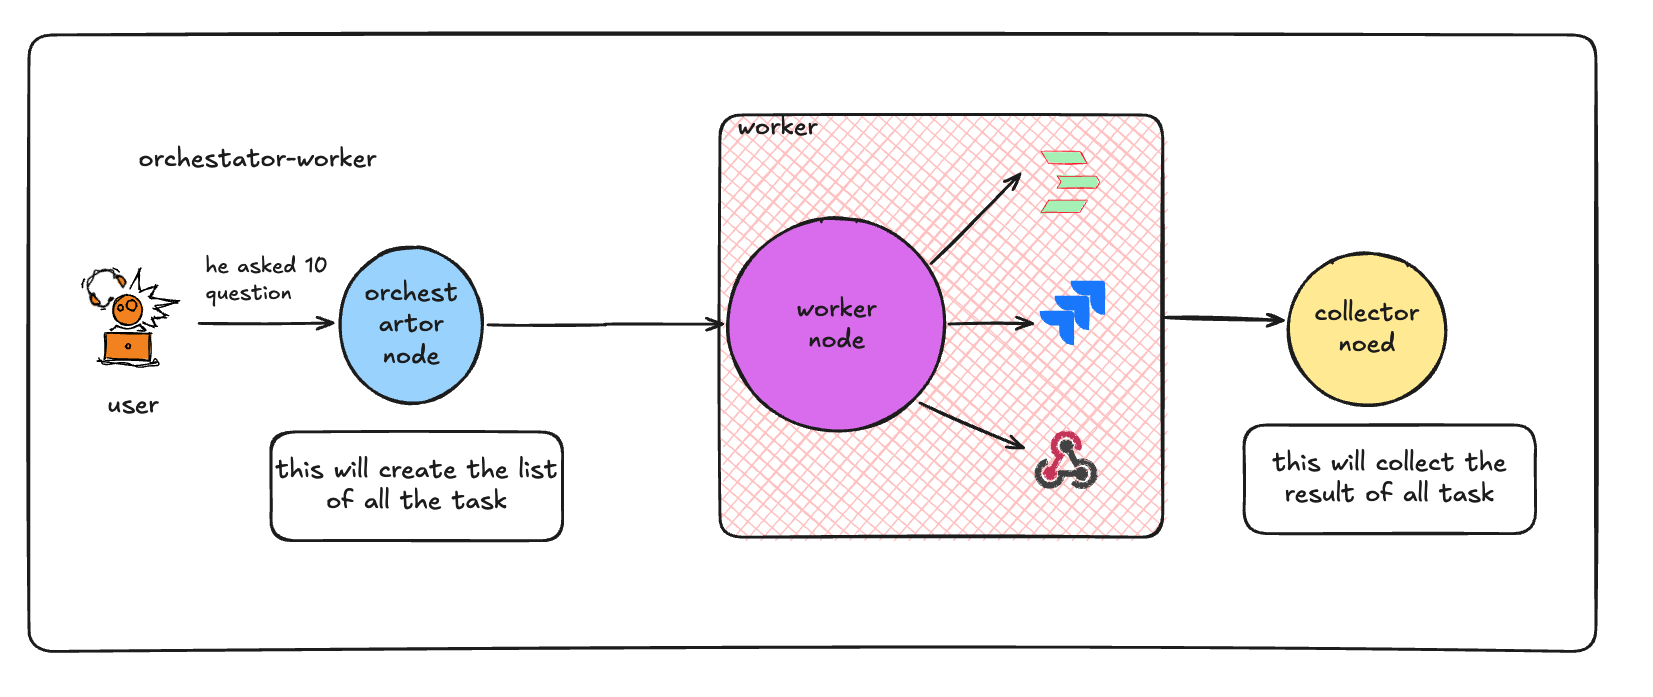

In [29]:
from langchain_openai import ChatOpenAI
import os
from dotenv import load_dotenv
load_dotenv(override=True)

os.environ["OPENAI_API_KEY"]=os.getenv("OPENAI_API_KEY")

In [30]:
llm = ChatOpenAI(model = "gpt-4o-mini")

In [31]:
from pydantic import BaseModel, Field
from typing import TypedDict,List

class llm_schema(BaseModel):
    tasks: List[str] = Field(...,description="A List of tasks to be performed by worker")



In [32]:
llm_schema = llm.with_structured_output(llm_schema)

In [33]:
from typing import TypedDict
class graph_schema(TypedDict):
    tasks: List[str]
    query: str
    results: List[str]
    summary: str
    

In [34]:

from langchain_core.prompts import ChatPromptTemplate
def orchestartor_node(state: graph_schema) -> graph_schema:

    # fetch thr user query

    uses_query = state['query']

    prompt = ChatPromptTemplate.from_messages(
        [
            (
                'system',""" 
                        "you are orchestrator that breaks down a user query into task for your worked
                    """   
            ),
            (
                "user", f""" 
                    USer query : {uses_query}. please generate one prompt per task for the worker to complete
                    retun the task in list format.
                """
            ),
        ]
    )


    chain = prompt | llm_schema

    response = chain.invoke({"query":uses_query})

    state['tasks'] = response.tasks

    return state

# WORKER NODE

In [35]:
def execute(query: str):

    response = llm.invoke(f"Please execute the task {query}")
    
    return response.content


In [36]:
from concurrent.futures import ThreadPoolExecutor
from unittest import result

def worker_node(state: graph_schema) -> graph_schema:
    tasks = state['tasks']

    results = []

    with ThreadPoolExecutor(max_workers=len(tasks)) as executor:
        result_futures=executor.map(execute,tasks)

        for result in result_futures:
            results.append(result)

    state['results'] = results

    return state
     

In [47]:
def collector(state: graph_schema) -> graph_schema:

    # fetch thr user query

    results = state['results'] 

    prompt = ChatPromptTemplate.from_messages(
        [
            ('system',"You are a collector that summarizes the results from the worker"),
            ("user", "Here are the results from the worker: {results}. Please summarize these results in a concise manner."),
        ]
    )


    chain = prompt | llm

    summary = chain.invoke({"results":results})

    state['summary'] = summary.content

    return state

In [48]:
from langgraph.graph import StateGraph, START, END

graph = StateGraph(graph_schema)

## register the nodes

graph.add_node("orchestartor_node",orchestartor_node)
graph.add_node("worker_node",worker_node)
graph.add_node("collector",collector)


## add the edges

graph.add_edge(START,"orchestartor_node")
graph.add_edge("orchestartor_node","worker_node")
graph.add_edge("worker_node","collector")
graph.add_edge("collector",END)



complete_graph = graph.compile()

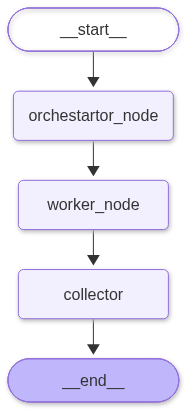

In [49]:
from IPython.display import Image,display

Image(complete_graph.get_graph().draw_mermaid_png())

In [50]:
complete_graph.invoke(
    {
        "query":""" 
                what is capital of india and what is the population of paris and what is capital of karnataka
                how to write python code for simple agent
        """,
        "tasks": [],
        "results": [],
        "summary": "",
    }
)

{'tasks': ['Find the capital of India.',
  'Find the population of Paris.',
  'Find the capital of Karnataka.',
  'Write Python code for a simple agent.'],
 'query': ' \n                what is capital of india and what is the population of paris and what is capital of karnataka\n                how to write python code for simple agent\n        ',
 'results': ['The capital of India is New Delhi.',
  "As of my last update in October 2021, the population of Paris was approximately 2.1 million people for the city proper. However, if you're interested in the larger metropolitan area, the population is around 11 million. For the most current figures, I recommend checking reliable sources such as official government statistics or recent demographic reports.",
  'The capital of Karnataka is Bengaluru.',
  'Certainly! Below is a simple Python agent that can perform a straightforward task: responding to user input. This agent can simulate a chatbot that answers basic questions or provides pred